# Ensembling

In [3]:
from sklearn.datasets import load_breast_cancer
import pandas as pd

cancer = load_breast_cancer()
     

X, y = cancer.data,cancer.target

In [4]:
X = pd.DataFrame(X, columns=cancer.feature_names)
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## Voting


### Hard Voting

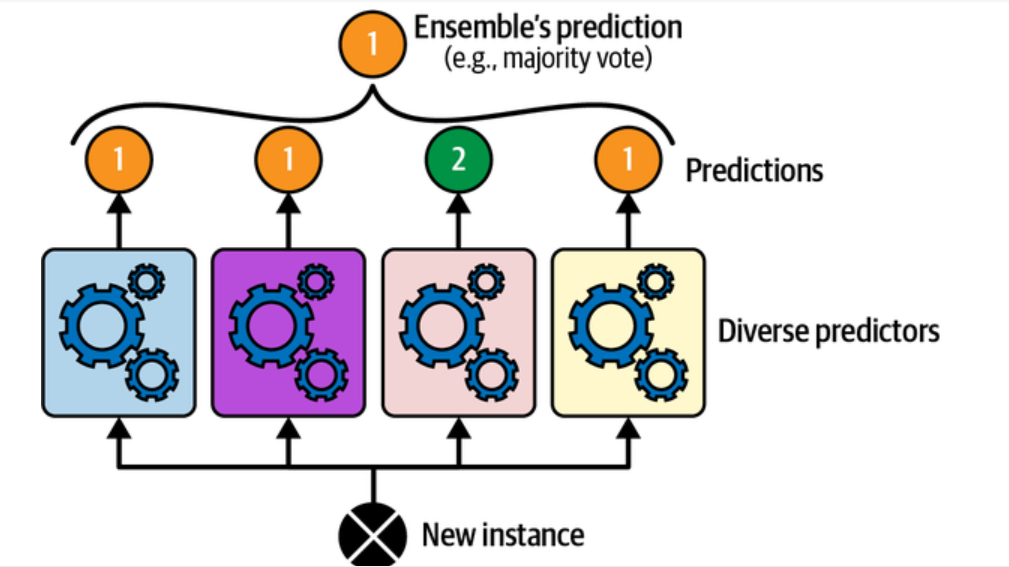

In [ ]:
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y)

In [ ]:
voting_clf_hard = VotingClassifier(
    estimators=[
        ('lr', LogisticRegression())
        ('knn', KNeighborsClassifier())
        ('dt', DecisionTreeClassifier())
    ], voting= 'soft', n_jobs=4
)

### Soft Voting

In [ ]:
voting_clf_soft = VotingClassifier(
    estimators=[
        ('lr', LogisticRegression())
        ('knn', KNeighborsClassifier())
        ('dt', DecisionTreeClassifier())
    ], voting= 'soft', n_jobs=4
)

In [ ]:
voting_clf_soft.fit(X_train)

## Bagging

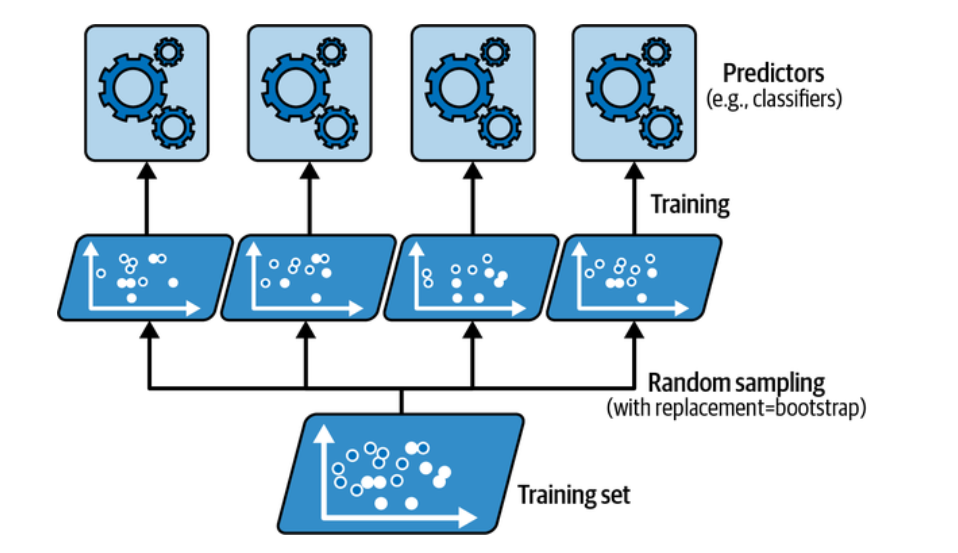

### Random forest

### Feature Importance

In [122]:
imp_df = pd.DataFrame({'col_name':X_train.columns,
                      'feature_importance':rf_clf.feature_importances_})

imp_df.sort_values(by='feature_importance', ascending=False)

,col_name,feature_importance
22,worst perimeter,0.124902
20,worst radius,0.116376
23,worst area,0.115678
27,worst concave points,0.109597
7,mean concave points,0.084294
26,worst concavity,0.059576
3,mean area,0.053114
6,mean concavity,0.050521
2,mean perimeter,0.047913
0,mean radius,0.047796


## Boosting

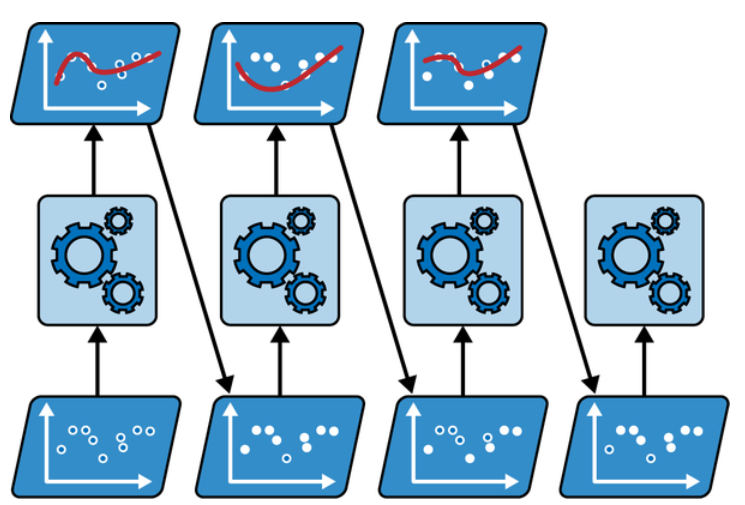

In [151]:
from sklearn.ensemble import AdaBoostClassifier


ada_clf = AdaBoostClassifier(LogisticRegression(), n_estimators=10, random_state=70)
ada_clf.fit(X_train, y_train)

C:\Users\dell\anaconda3\envs\ga\lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\dell\anaconda3\envs\ga\lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regres

AdaBoostClassifier(estimator=LogisticRegression(), n_estimators=10,
                   random_state=70)

In [152]:
y_pred = ada_clf.predict(X_val)

recall_score(y_val, y_pred, pos_label=0)

0.925

In [153]:
f1_score(y_val, y_pred, pos_label=0)

0.925

## Stacking

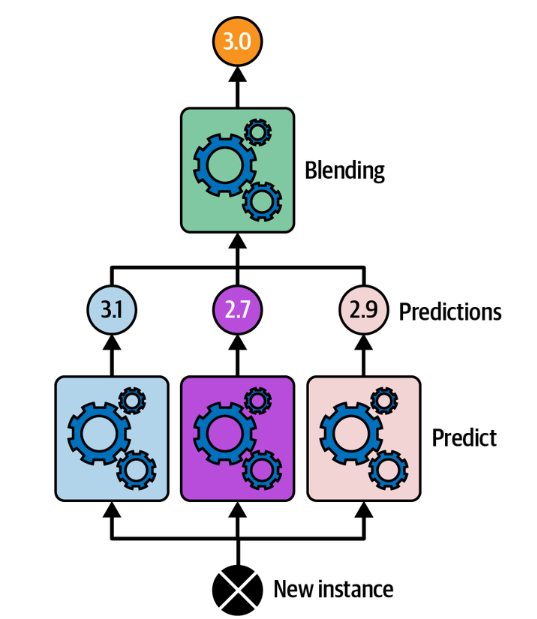

In [156]:
from sklearn.ensemble import StackingClassifier


stk_clf = StackingClassifier([('lr', LogisticRegression()),
                              ('dt', DecisionTreeClassifier()),
                              ('knn', KNeighborsClassifier())],
                            
                             final_estimator=LogisticRegression()
                            )
stk_clf.fit(X_train, y_train)

C:\Users\dell\anaconda3\envs\ga\lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\dell\anaconda3\envs\ga\lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regres

StackingClassifier(estimators=[('lr', LogisticRegression()),
                               ('dt', DecisionTreeClassifier()),
                               ('knn', KNeighborsClassifier())],
                   final_estimator=LogisticRegression())

In [158]:
y_pred = stk_clf.predict(X_val)

recall_score(y_val, y_pred, pos_label=0)

0.85

In [159]:
f1_score(y_val, y_pred, pos_label=0)

0.9066666666666666